# A camera's own words

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pless/register-gap-demo/blob/main/demo.ipynb)

A camera has its own words. Viewers of a bear cam write "903" for a bear and "begging" for an action. A frozen image-text model does not know these words. Two small linear maps, trained on a few thousand (caption, frame) pairs, teach the model those words.

The maps are not a new kind of model. They are a small linear adapter on frozen embeddings, in the family of CLIP-Adapter. The encoder is SigLIP2-base (`google/siglip2-base-patch16-256`), and it does not change.

This notebook has four parts. Part 1 needs no GPU. Parts 2 to 4 use the encoder, so a GPU makes them faster.

In [1]:
# Set-up. On Colab, install a recent transformers and get the code of this demo.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers"], check=True)
if not os.path.exists("embed.py"):
    if not os.path.exists("register-gap-demo"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pless/register-gap-demo"], check=True)
    os.chdir("register-gap-demo")

In [2]:
import hashlib
import json
import re
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from embed import embed_images, embed_texts, load_encoder
from evaluate import heatmap, recall, word_auc
from maps import TwoMaps, apply_maps, train_maps


def show_recall(name, r):
    print(f"{name:10s} R@1 {r['R@1']:.3f}   R@10 {r['R@10']:.3f}   R@50 {r['R@50']:.3f}   median rank {r['median rank']:.0f}")

## 1. Two maps in one minute (bear cam, no GPU)

Viewers of the Brooks Falls bear cam (explore.org) take a snapshot of the live camera and write a short caption. The file `data/bears.npz` has the frozen embeddings of 4,206 such (caption, snapshot) pairs from July and August 2026. We train the two maps on them and test them on days that the maps did not see.

Each map is `phi(x) = normalize(x + W x + b)`. W and b start at zero, so the maps start as the frozen encoder. The loss is a contrastive loss: a caption must be nearer to its own frame than to the other frames of the batch. After each epoch, `train_maps` measures R@10 on the validation pairs and keeps the best epoch.

In [3]:
bears = np.load("data/bears.npz")
text = bears["text"].astype(np.float32)
image = bears["image"].astype(np.float32)
split = bears["split"]
train, val, test = split == "train", split == "val", split == "test"
print("pairs: train", train.sum(), "  validation", val.sum(), "  test", test.sum())

maps = train_maps(text[train], image[train], text[val], image[val])
show_recall("frozen", recall(text[test], image[test]))
show_recall("two maps", recall(*apply_maps(maps, text[test], image[test])))

pairs: train 2945   validation 785   test 476


frozen     R@1 0.013   R@10 0.061   R@50 0.223   median rank 166
two maps   R@1 0.021   R@10 0.137   R@50 0.342   median rank 86


Each test caption searches all the test frames. R@10 is the share of test captions whose own frame is in the top 10.

Now we use single words as queries. A held-out frame is positive for a word if a viewer used that word, or a word of the same family, for the frame. AUC is the chance that a positive frame scores above a negative frame: 0.5 is chance and 1.0 is perfect. The held-out frames come from 16 days. On the validation days, the validation pairs only chose the epoch.

In [4]:
rows = [json.loads(line) for line in open("data/bears.jsonl")]
frames = {}
for i, row in enumerate(rows):
    if row["split"] != "train":
        frame = frames.setdefault(row["snapshot_url"], {"row": i, "actions": set()})
        frame["actions"].update(row["actions"])
frames = list(frames.values())
frame_image = image[[f["row"] for f in frames]]

words = np.load("data/bear_words.npz")
labels = np.array([[action in f["actions"] for f in frames] for action in words["action"]])
viewer_before = word_auc(words["viewer_vector"], frame_image, labels)
viewer_after = word_auc(*apply_maps(maps, words["viewer_vector"], frame_image), labels)
plain_before = word_auc(words["plain_vector"], frame_image, labels)
plain_after = word_auc(*apply_maps(maps, words["plain_vector"], frame_image), labels)

print(f"{len(frames)} held-out frames. AUC before -> after the maps.")
print(f"{'viewer word':14s} {'frames':>6s}   {'viewer word':12s}   plain English description")
for j in range(len(labels)):
    print(f"{words['viewer_word'][j]:14s} {labels[j].sum():6d}   {viewer_before[j]:.2f} -> {viewer_after[j]:.2f}   {plain_before[j]:.2f} -> {plain_after[j]:.2f}   {words['plain_text'][j]}")
print(f"{'mean':14s} {'':6s}   {viewer_before.mean():.2f} -> {viewer_after.mean():.2f}   {plain_before.mean():.2f} -> {plain_after.mean():.2f}")

1203 held-out frames. AUC before -> after the maps.
viewer word    frames   viewer word    plain English description
catch             424   0.56 -> 0.59   0.57 -> 0.64   a bear holding a salmon in its mouth
eating            261   0.64 -> 0.64   0.60 -> 0.60   a bear eating a fish
sleeping          159   0.87 -> 0.91   0.90 -> 0.90   a bear lying down asleep
fishing           145   0.41 -> 0.55   0.45 -> 0.48   a bear standing in the river looking for fish
begging           113   0.38 -> 0.72   0.48 -> 0.63   a bear waiting next to another bear that has a fish
sparring           47   0.50 -> 0.67   0.56 -> 0.56   two bears fighting
playing            34   0.71 -> 0.68   0.72 -> 0.72   two young bears playing
shaking            15   0.72 -> 0.67   0.78 -> 0.64   a bear shaking water off its fur
diving             28   0.47 -> 0.45   0.44 -> 0.53   a bear plunging its head under water
snorkeling          8   0.88 -> 0.93   0.70 -> 0.79   a bear with its face under the water
high-grading

The maps help most with the words of the bear cam, such as "begging" and "sparring". Plain words, such as "sleeping", work well already. Some words lose a little: "playing", "shaking" and "diving".

Below are the top 5 held-out frames for "begging", before and after the maps. A green border shows that a viewer used the word, or a word of the same family such as "stealing", for that frame.

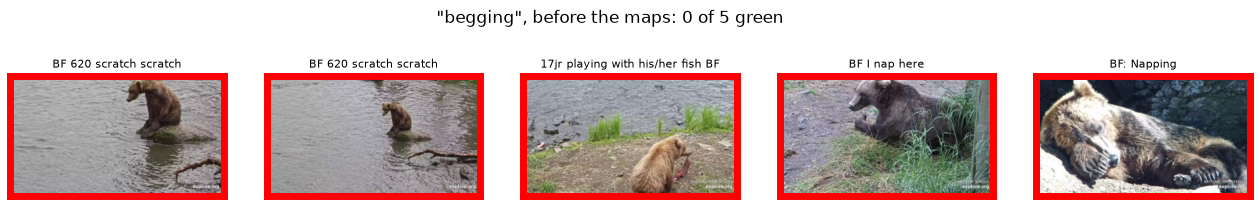

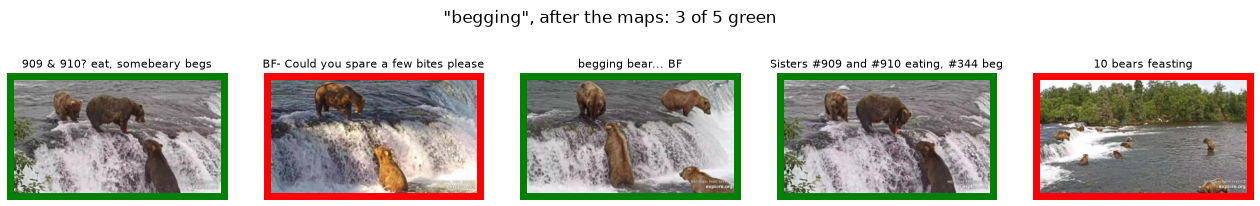

In [5]:
j = list(words["viewer_word"]).index("begging")
mapped_word, mapped_frames = apply_maps(maps, words["viewer_vector"][j], frame_image)
for title, scores in (("before the maps", frame_image @ words["viewer_vector"][j]), ("after the maps", mapped_frames @ mapped_word)):
    top = np.argsort(-scores)[:5]
    fig, axes = plt.subplots(1, 5, figsize=(16, 2.6))
    for ax, t in zip(axes, top):
        row = rows[frames[t]["row"]]
        ax.imshow(Image.open(urlopen(row["thumbnail_url"])))
        for side in ax.spines.values():
            side.set_color("green" if labels[j, t] else "red")
            side.set_linewidth(5)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(row["caption"][:38], fontsize=8)
    fig.suptitle(f'"begging", {title}: {labels[j, top].sum()} of 5 green')
    plt.show()

## 2. From raw pairs (Duluth harbor, 2012 to 2026)

The Duluth Harbor Cam blog posts one or two sentences for each ship that comes or goes. Each post has a frame from one of its harbor cameras. The public repository `pless/duluth-harbor-cam-captions` has 5,077 such pairs from 2012 to 2026, with frames 640 px wide (a download of about 270 MB). Here we start from the raw frames and captions.

We split the pairs by day, never at random. Frames from one day look alike. A random split puts near copies of the test frames in the training data, and then the test score is too high.

In [6]:
if not os.path.exists("duluth-harbor-cam-captions"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pless/duluth-harbor-cam-captions"], check=True)


def split_of(day):
    """Split by day with a hash of the date: 70% train, 15% validation, 15% test."""
    h = int(hashlib.md5(day.encode()).hexdigest(), 16) % 100
    if h < 70:
        return "train"
    if h < 85:
        return "val"
    return "test"


pairs = [json.loads(line) for line in open("duluth-harbor-cam-captions/pairs.jsonl")]
pairs = [p for p in pairs if p["is_cam"]]
captions = [" ".join(p["caption"].split()) for p in pairs]
paths = ["duluth-harbor-cam-captions/" + p["image"] for p in pairs]
dsplit = np.array([split_of(p["date"][:10]) for p in pairs])
dtrain, dval, dtest = dsplit == "train", dsplit == "val", dsplit == "test"
print("pairs: train", dtrain.sum(), "  validation", dval.sum(), "  test", dtest.sum())
print("example caption:", captions[0])

pairs: train 3546   validation 789   test 742
example caption: Polstream Dabie arrived in Duluth this morning to load grain.


The next cell embeds the 5,077 frames and captions with the frozen encoder. Then we train the maps and measure the recall on the test days.

In [7]:
model, processor = load_encoder()
print("device:", model.device)
dtext = embed_texts(model, processor, captions)
dimage = embed_images(model, processor, paths)

dmaps = train_maps(dtext[dtrain], dimage[dtrain], dtext[dval], dimage[dval])
show_recall("frozen", recall(dtext[dtest], dimage[dtest]))
show_recall("two maps", recall(*apply_maps(dmaps, dtext[dtest], dimage[dtest])))

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

device: mps:0


frozen     R@1 0.042   R@10 0.121   R@50 0.253   median rank 202
two maps   R@1 0.127   R@10 0.418   R@50 0.751   median rank 15


**Caution: names on the screen.** Many frames carry the ship name as text on the image. In 60 random frames, we counted 18 (about 1 in 3) with the name as an overlay. The encoder can read some of this text, and the maps can learn to use it. Thus we test two groups of words. Ship names can be on the screen. Cargo and place words are not part of the overlay.

A ship name is a label of the blog that starts a caption as "<name> arrived" or "<name> departed". We use the 10 ship names that the most test captions use.

In [8]:
test_rows = np.where(dtest)[0]


def contains(caption, word):
    """True if the caption has the word as whole words. Case and periods do not count."""
    pattern = r"(?<!\w)" + re.escape(word.lower().replace(".", "")) + r"(?!\w)"
    return re.search(pattern, caption.lower().replace(".", "")) is not None


def word_table(word_list):
    vectors = embed_texts(model, processor, word_list)
    labels = np.array([[contains(captions[i], w) for i in test_rows] for w in word_list])
    before = word_auc(vectors, dimage[test_rows], labels)
    after = word_auc(*apply_maps(dmaps, vectors, dimage[test_rows]), labels)
    print(f"{'word':22s} {'test frames':>11s}   AUC before -> after")
    for w, n, b, a in zip(word_list, labels.sum(1), before, after):
        print(f"{w:22s} {n:11d}   {b:.2f} -> {a:.2f}")


starts = set()
for caption in captions:
    m = re.match(r"(.+?) (arrived|departed)\b", caption.replace(".", ""))
    if m:
        starts.add(m.group(1).lower())
names = {" ".join(label.replace(".", "").split()) for p in pairs for label in p["labels"]}
ships = [name for name in names if name.lower() in starts]
positives = {name: sum(contains(captions[i], name) for i in test_rows) for name in ships}
ships = sorted(ships, key=lambda name: (-positives[name], name))[:10]

print("Ship names (they can be on the screen)")
word_table(ships)
print()
print("Cargo, places and ice (not part of the overlay)")
word_table(["grain", "coal", "limestone", "cement", "wheat", "iron ore pellets", "Two Harbors", "Superior", "ice"])

Ship names (they can be on the screen)
word                   test frames   AUC before -> after
Paul R Tregurtha                63   0.64 -> 0.70
James R Barker                  49   0.39 -> 0.53
American Century                43   0.56 -> 0.53
Mesabi Miner                    31   0.66 -> 0.56
Arthur M Anderson               27   0.42 -> 0.42
Indiana Harbor                  25   0.52 -> 0.36
Hon James L Oberstar            23   0.67 -> 0.82
John G Munson                   21   0.60 -> 0.79
Lee A Tregurtha                 20   0.66 -> 0.77
American Integrity              19   0.47 -> 0.45

Cargo, places and ice (not part of the overlay)
word                   test frames   AUC before -> after
grain                           42   0.55 -> 0.73
coal                            57   0.56 -> 0.52
limestone                       35   0.53 -> 0.72
cement                           6   0.48 -> 0.73
wheat                            8   0.36 -> 0.63
iron ore pellets                51   0.58 -> 0.4

Full captions gain the most: R@10 goes from 0.12 to 0.42. Single words gain less. Most cargo and place words improve, such as "Two Harbors" (0.53 to 0.88) and "limestone" (0.53 to 0.72). Three words lose: "coal", "iron ore pellets" and "ice". The results for ship names differ: five improve, four lose, and one stays the same.

## 3. Where does a word point? (bear cam)

Viewers name bears with park codes, such as "903", and with nicknames, such as "Gully". Here we download 12 held-out frames with one bear. For each frame, we ask which of the 256 patches matches the code or the nickname best. The heat shows the cosine of the word with each patch. The cyan box is the bear, and the green circle is the hottest patch.

Maps that see only full frames do not point. On 355 held-out frames with one bear, the hottest patch is on the bear in 18% of the frames before the maps. After them, it is 19%. We trained the maps in `data/bear_set_maps.npz` with a set score, which matches each word of a caption to its best patch. With these maps, the hottest patch is on the bear in 79% of the 355 frames (chance 31%). Part 5 trains such maps with `sets.py`.

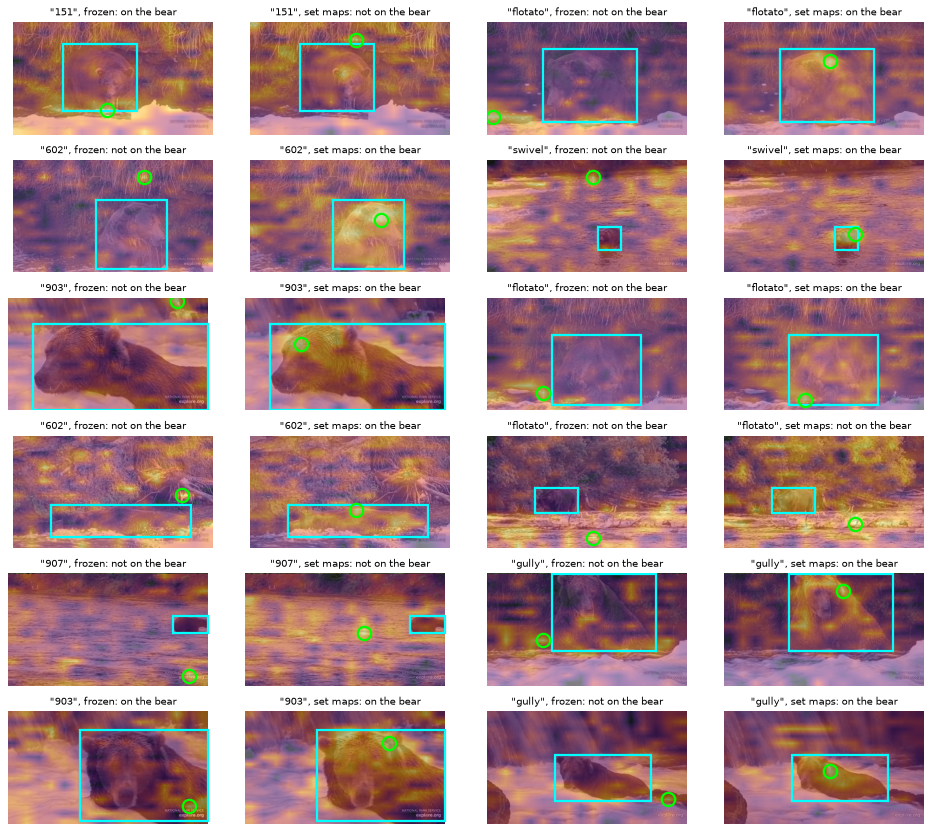

hottest patch on the bear: 2 of 12 frozen, 9 of 12 with the set maps


In [9]:
pointing = [json.loads(line) for line in open("data/bear_pointing.jsonl")]
snapshots = [Image.open(urlopen(p["snapshot_url"])).convert("RGB") for p in pointing]
_, patches = embed_images(model, processor, snapshots, with_patches=True)
queries = embed_texts(model, processor, [p["query"] for p in pointing])

z = np.load("data/bear_set_maps.npz")
set_maps = TwoMaps(768)
set_maps.load_state_dict({
    "text_map.weight": torch.tensor(z["Wt"], dtype=torch.float32),
    "text_map.bias": torch.tensor(z["bt"], dtype=torch.float32),
    "image_map.weight": torch.tensor(z["Wi"], dtype=torch.float32),
    "image_map.bias": torch.tensor(z["bi"], dtype=torch.float32),
})


def hottest(heat):
    """The center (x, y) of the hottest patch, from 0 to 1."""
    row, col = np.unravel_index(np.argmax(heat), heat.shape)
    return (col + 0.5) / 16, (row + 0.5) / 16


hits = {"frozen": 0, "set maps": 0}
fig, axes = plt.subplots(6, 4, figsize=(12, 10.5), dpi=80)
for k, p in enumerate(pointing):
    mapped_query, mapped_patches = apply_maps(set_maps, queries[k], patches[k])
    for c, (name, heat) in enumerate((("frozen", heatmap(patches[k], queries[k])), ("set maps", heatmap(mapped_patches, mapped_query)))):
        ax = axes[k // 2, 2 * (k % 2) + c]
        width, height = snapshots[k].size
        x0, y0, x1, y1 = p["box"]
        x, y = hottest(heat)
        hit = x0 <= x <= x1 and y0 <= y <= y1
        hits[name] += hit
        ax.imshow(snapshots[k])
        ax.imshow(heat, cmap="inferno", alpha=0.5, extent=(0, width, height, 0), interpolation="bilinear")
        ax.add_patch(plt.Rectangle((x0 * width, y0 * height), (x1 - x0) * width, (y1 - y0) * height, fill=False, edgecolor="cyan", linewidth=2))
        ax.plot(x * width, y * height, "o", markersize=12, markerfacecolor="none", markeredgecolor="lime", markeredgewidth=2)
        ax.set_title(f'"{p["query"]}", {name}: {"on the bear" if hit else "not on the bear"}', fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()
print("hottest patch on the bear:", hits["frozen"], "of 12 frozen,", hits["set maps"], "of 12 with the set maps")

## 4. Your own camera

Write your pairs as a JSON-lines file, with one line for each (frame, caption) pair. Each line has three fields: `image` (a file path), `caption`, and `time` (ISO text, such as `2026-08-31T17:06`). The function `run` splits the pairs by day, embeds them, trains the maps and prints the recall on the test days. Here we run it on the Duluth pairs from 2023 to 2026 (713 pairs).

In [10]:
def run(pairs_jsonl):
    """pairs_jsonl: a file with one JSON object for each pair: image (a file path), caption, time (ISO text).
    Splits the pairs by day, trains the two maps and prints the recall on the test days. Returns the maps."""
    pairs = [json.loads(line) for line in open(pairs_jsonl)]
    split = np.array([split_of(p["time"][:10]) for p in pairs])
    train, val, test = split == "train", split == "val", split == "test"
    print("pairs: train", train.sum(), "  validation", val.sum(), "  test", test.sum())
    text = embed_texts(model, processor, [p["caption"] for p in pairs])
    image = embed_images(model, processor, [p["image"] for p in pairs])
    maps = train_maps(text[train], image[train], text[val], image[val])
    show_recall("frozen", recall(text[test], image[test]))
    show_recall("two maps", recall(*apply_maps(maps, text[test], image[test])))
    return maps


with open("my_pairs.jsonl", "w") as f:
    for p, caption, path in zip(pairs, captions, paths):
        if p["date"] >= "2023":
            f.write(json.dumps({"image": path, "caption": caption, "time": p["date"]}) + "\n")
my_maps = run("my_pairs.jsonl")

pairs: train 511   validation 99   test 103


frozen     R@1 0.233   R@10 0.505   R@50 0.874   median rank 10
two maps   R@1 0.252   R@10 0.757   R@50 0.961   median rank 3


### Advice

- Split by time or by visit, never at random.
- Start with 500 to 5,000 pairs. More pairs give more words.
- Query with the words of the people who wrote the captions. The maps follow the writer, not the camera.
- Plain words already work. The gain is in the words of the camera.
- Look for on-screen text, such as time stamps and labels. The maps will use it.

## 5. Maps over phrases and patches (optional, Duluth)

The same two maps can also act on parts. The text map acts on each phrase of a caption, and the image map acts on each of the 256 patches of a frame. The set score adds, for each phrase, its best match among the patches. Two learned numbers set how much this term counts (`lam`) and how hard the best match is (`tau`). The maps of part 3 learned to point with this score. The file `sets.py` has the score and its training loop.

On a laptop with Apple MPS, part 5 takes about 6 minutes, most of it for the patches and the training. To skip this part, set `RUN_PART_5 = False` in the next cell.

In [11]:
RUN_PART_5 = True

In [12]:
def phrases_of(caption, doc):
    """The phrases of a caption, as in the research code: the noun chunks of spaCy, with no pronouns.
    A caption with one chunk or none is split on "&", "and", commas and slashes. At most 32 phrases."""
    out = []
    for chunk in doc.noun_chunks:
        text = chunk.text.strip(" .,;:!#'\"")
        if len(text) >= 3 and chunk.root.pos_ != "PRON":
            out.append(text)
    if len(out) <= 1:
        parts = [part.strip(" .,;:!#'\"") for part in re.split(r"\s*(?:&|\band\b|,|/|\+)\s*", caption)]
        parts = [part for part in parts if len(re.findall(r"[A-Za-z]", part)) >= 3]
        if len(parts) > 1:
            out = parts
    if not out or (len(out) == 1 and len(caption.split()) <= 5 and len(out[0]) < len(caption)):
        out = [caption[:200]]
    unique = {}
    for text in out:
        unique.setdefault(text.lower(), text)
    return list(unique.values())[:32]


if RUN_PART_5:
    import spacy

    from evaluate import auc_of_scores, recall_of_scores
    from sets import set_scores, train_set_maps, word_scores

    if not spacy.util.is_package("en_core_web_sm"):
        spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
    phrase_lists = [phrases_of(c, doc) for c, doc in zip(captions, nlp.pipe(captions, batch_size=256))]
    phrase_texts = sorted({t for ps in phrase_lists for t in ps})
    phrase_vectors = dict(zip(phrase_texts, embed_texts(model, processor, phrase_texts)))
    width = max(len(ps) for ps in phrase_lists)
    phrases = np.zeros((len(captions), width, 768), np.float16)
    phrase_mask = np.zeros((len(captions), width), bool)
    for i, ps in enumerate(phrase_lists):
        for k, t in enumerate(ps):
            phrases[i, k] = phrase_vectors[t]
            phrase_mask[i, k] = True
    print(len(phrase_texts), "different phrases;", round(phrase_mask.sum(1).mean(), 1), "phrases for each caption on average")
    print("example:", captions[0], "->", phrase_lists[0])
    _, dpatches = embed_images(model, processor, paths, with_patches=True)
    print("patches:", dpatches.shape, dpatches.dtype)

7240 different phrases; 3.9 phrases for each caption on average
example: Polstream Dabie arrived in Duluth this morning to load grain. -> ['Polstream Dabie', 'Duluth', 'grain']


patches: (5077, 256, 768) float16


Now we train the set maps on the training days. After each epoch, `train_set_maps` prints the R@10 on the validation pairs and the two learned numbers, and it keeps the best epoch.

In [13]:
if RUN_PART_5:
    train_rows = np.where(dtrain)[0]
    val_rows = np.where(dval)[0]
    set_model = train_set_maps(dtext, phrases, phrase_mask, dimage, dpatches, train_rows, val_rows)
    show_recall("frozen", recall(dtext[dtest], dimage[dtest]))
    show_recall("two maps", recall(*apply_maps(dmaps, dtext[dtest], dimage[dtest])))
    show_recall("set maps", recall_of_scores(set_scores(set_model, dtext, phrases, phrase_mask, dimage, dpatches, test_rows)))

epoch  1: validation R@10 0.188, lam 1.35, tau 0.0372


epoch  2: validation R@10 0.246, lam 1.90, tau 0.0263


epoch  3: validation R@10 0.292, lam 2.68, tau 0.0193


epoch  4: validation R@10 0.317, lam 3.56, tau 0.0160


epoch  5: validation R@10 0.346, lam 4.28, tau 0.0148


epoch  6: validation R@10 0.359, lam 4.87, tau 0.0140


... (22 outputs left out)

epoch 29: validation R@10 0.376, lam 14.57, tau 0.0042


epoch 30: validation R@10 0.371, lam 15.05, tau 0.0035


frozen     R@1 0.042   R@10 0.121   R@50 0.253   median rank 202
two maps   R@1 0.127   R@10 0.418   R@50 0.751   median rank 15


set maps   R@1 0.124   R@10 0.394   R@50 0.710   median rank 19


For a single word, the set maps use two cosines. The score is the cosine with the full frame plus `lam` times the cosine with the best patch.

In [14]:
def set_word_table(word_list):
    vectors = embed_texts(model, processor, word_list)
    labels = np.array([[contains(captions[i], w) for i in test_rows] for w in word_list])
    frozen_auc = word_auc(vectors, dimage[test_rows], labels)
    maps_auc = word_auc(*apply_maps(dmaps, vectors, dimage[test_rows]), labels)
    sets_auc = auc_of_scores(word_scores(set_model, vectors, dimage[test_rows], dpatches[test_rows]), labels)
    print(f"{'word':22s} {'test frames':>11s}   AUC: frozen, two maps, set maps")
    for w, n, a, b, c in zip(word_list, labels.sum(1), frozen_auc, maps_auc, sets_auc):
        print(f"{w:22s} {n:11d}   {a:.2f}   {b:.2f}   {c:.2f}")


if RUN_PART_5:
    print("Ship names (they can be on the screen)")
    set_word_table(ships)
    print()
    print("Cargo, places and ice (not part of the overlay)")
    set_word_table(["grain", "coal", "limestone", "cement", "wheat", "iron ore pellets", "Two Harbors", "Superior", "ice"])

Ship names (they can be on the screen)


word                   test frames   AUC: frozen, two maps, set maps
Paul R Tregurtha                63   0.64   0.70   0.83
James R Barker                  49   0.39   0.53   0.64
American Century                43   0.56   0.53   0.69
Mesabi Miner                    31   0.66   0.56   0.79
Arthur M Anderson               27   0.42   0.42   0.48
Indiana Harbor                  25   0.52   0.36   0.50
Hon James L Oberstar            23   0.67   0.82   0.87
John G Munson                   21   0.60   0.79   0.86
Lee A Tregurtha                 20   0.66   0.77   0.84
American Integrity              19   0.47   0.45   0.59

Cargo, places and ice (not part of the overlay)
word                   test frames   AUC: frozen, two maps, set maps
grain                           42   0.55   0.73   0.84
coal                            57   0.56   0.52   0.68
limestone                       35   0.53   0.72   0.84
cement                           6   0.48   0.73   0.86
wheat                        

The heat map below shows where the set maps find a place that the frames show: "canal", the Duluth ship canal. The frames are the first 4 test frames whose post uses the word. The green circle is the hottest patch.

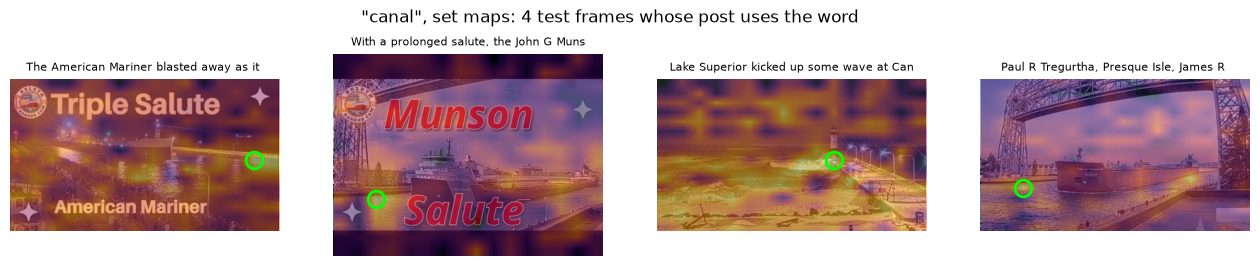

In [15]:
if RUN_PART_5:
    word = "canal"
    vector = embed_texts(model, processor, [word])
    frames_with_word = [i for i in test_rows if contains(captions[i], word)][:4]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3))
    for ax, i in zip(axes, frames_with_word):
        frame = Image.open(paths[i]).convert("RGB")
        mapped_word, mapped_patches = apply_maps(set_model.maps, vector[0], dpatches[i])
        heat = heatmap(mapped_patches, mapped_word)
        x, y = hottest(heat)
        width, height = frame.size
        ax.imshow(frame)
        ax.imshow(heat, cmap="inferno", alpha=0.5, extent=(0, width, height, 0), interpolation="bilinear")
        ax.plot(x * width, y * height, "o", markersize=12, markerfacecolor="none", markeredgecolor="lime", markeredgewidth=2)
        ax.axis("off")
        ax.set_title(captions[i][:40], fontsize=8)
    fig.suptitle(f'"{word}", set maps: 4 test frames whose post uses the word')
    plt.show()

The set maps find full captions a little less well than the two maps: R@10 0.39 against 0.42. But all 19 single words score higher with the set maps than with the two maps. For example, "grain" goes from 0.73 to 0.84 and "coal" from 0.52 to 0.68. The ship names gain too. Part of that gain can come from the names on the screen, because a phrase can match the patch that shows the name. Two words stay near or below the frozen model: "ice" and "Indiana Harbor". The stored research run gave the same picture: R@10 0.40 against 0.45, "grain" 0.85 and "coal" 0.71.

**Data.** Bear cam: snapshots and viewer captions from explore.org (Brooks Falls, Katmai National Park, 2026). Duluth: frames and posts of the Duluth Harbor Cam / LSMMA (2012 to 2026). To ask us to remove an item, open an issue at https://github.com/pless/register-gap-demo/issues.